# preliminaries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn import svm
from sklearn.metrics import accuracy_score, confusion_matrix
from pathlib import Path
import seaborn as sns

# import the data

In [2]:
path = Path("./Data")

pca = "4"
balanced = "unbalanced"
percent = "1"

In [3]:
# Make file extension based on what run we're doing
extension = pca + "PCA_" + balanced + "_" + percent + "percent"
extension

'4PCA_unbalanced_1percent'

In [4]:
X = pd.read_csv(path / ("X_" + extension + ".csv"))
y = pd.read_csv(path / ("y_" + extension + ".csv"))
X.shape, y.shape

((2722, 4), (2722, 1))

In [5]:
y.value_counts()

Label
True     2551
False     171
Name: count, dtype: int64

In [6]:
#convert to int labels
y1 = 1 - y

#1 is false and 0 is true
y1.shape  

X1 = X #idk really

# Training time

In [7]:
def mcc_score(c1):
    n1 = c1[0, 0] + c1[0, 1]
    n2 = c1[1, 0] + c1[1, 1]
    n3 = c1[0, 0] + c1[1, 0]
    n4 = c1[0, 1] + c1[1, 1]
    return (c1[0, 0] * c1[1, 1] - c1[0, 1] * c1[1, 0]) / np.sqrt(n1 * n2 * n3 * n4)

In [8]:
kernels = ['linear', 'rbf', "poly", "sigmoid"]
C = 1.0
g = 0.69
deg = 7
coef = 0.2

test_size = 0.4 #percentage of the data to save for testing
n_splits = 10 #number of times to split the data
# They did 7 originally but I found that choice strange

stats = []

splitter = sklearn.model_selection.StratifiedKFold(n_splits=n_splits, shuffle=True)
#splitter = sklearn.model_selection.StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=0)
# for g in gamma:
for kernel in kernels:
    for i in range(10):
        clf = svm.SVC(kernel=kernel, gamma=g, C=C, degree=deg, coef0=coef, class_weight='balanced')
        # if kernel == 'linear' or kernel == 'rbf':
        #     clf = svm.SVC(kernel=kernel, gamma=g, C=C, class_weight='balanced')
        # elif kernel == 'poly':
        #     clf = svm.SVC(kernel=kernel, degree=deg, gamma=g, C=C, class_weight='balanced')
        #             #print("===========\n", kernel)
        # elif kernel == 'sigmoid':
        #     clf = svm.SVC(kernel=kernel, gamma=g, C=C, class_weight='balanced')
    
        for train_index, test_index in splitter.split(X1, y1):
            X_train, X_test = X1.iloc[train_index], X1.iloc[test_index]
            y_train, y_test = y1.iloc[train_index], y1.iloc[test_index]
    
            X_train = X_train.to_numpy()
            X_test = X_test.to_numpy()
            y_train = np.ravel(y_train)
            y_test = np.ravel(y_test)
    
            clf.fit(X_train, y_train)
    
                            #metrics
            for t in [['train', X_train, y_train], ['test', X_test, y_test]]:
                #print(t)
                y_pred = clf.predict(t[1])
    
                confusion = confusion_matrix(t[2], y_pred, normalize='true')
                accuracy = accuracy_score(t[2], y_pred)
    
                # print("\nmcc:", mcc_score(confusion))
                # print("confusion_matrix:\n", confusion)
                # print("accuracy:", accuracy)
                dict = {'kernel': kernel, 
                        'phase' : t[0],
                        'mcc': mcc_score(confusion),#sklearn.metrics.matthews_corrcoef(y_test, y_pred),#, 
                        'confusion_matrix': confusion, 
                        'true_healthy' : confusion[0, 0],
                        'false_healthy': confusion[1, 0],
                        'true_failure': confusion[1, 1],
                        'false_failure': confusion[0, 1],
                        'accuracy': accuracy,
                        'precision': confusion[1,1] / (confusion[1,1] + confusion[0,1]),
                        'recall': confusion[1,1] / (confusion[1,1] + confusion[1,0])}
                        #'gamma': g}
                stats.append(dict)

stats_df = pd.DataFrame(stats)
#stats_df

In [9]:
stats_stdv = stats_df.groupby(['kernel', 'phase']).describe(percentiles=[.95])

In [10]:
stats_stdv

mcc                                                    \
               count      mean       std       min       50%       95%   
kernel  phase                                                            
linear  test   100.0  0.182438  0.103799 -0.149207  0.177386  0.361436   
        train  100.0  0.213813  0.034441  0.124531  0.222613  0.257142   
poly    test   100.0  0.383251  0.120592  0.118842  0.392358  0.554605   
        train  100.0  0.738226  0.011787  0.706560  0.739038  0.758330   
rbf     test   100.0  0.532848  0.089421  0.206103  0.539114  0.666259   
        train  100.0  0.654281  0.012517  0.615626  0.654027  0.674206   
sigmoid test   100.0 -0.252711  0.115009 -0.669973 -0.254358 -0.059863   
        train  100.0 -0.249703  0.017944 -0.281362 -0.252358 -0.214403   

                        true_healthy                      ... precision  \
                    max        count      mean       std  ...       50%   
kernel  phase                                             ...             
linear  test   0.388343        100.0  0.683842  0.079580  ...  0.608932   
        train  0.269749        100.0  0.685480  0.078549  ...  0.625230   
poly    test   0.707107        100.0  0.813603  0.023597  ...  0.750000   
        train  0.763829        100.0  0.836648  0.009287  ...  0.846428   
rbf     test   0.738549        100.0  0.685455  0.029305  ...  0.728271   
        train  0.686837        100.0  0.693780  0.009052  ...  0.754098   
sigmoid test   0.075094        100.0  0.373347  0.032603  ...  0.378606   
        train -0.201461        100.0  0.375252  0.009669  ...  0.373383   

                                  recall                                \
                    95%       max  count      mean       std       min   
kernel  phase                                                            
linear  test   0.678759  0.708661  100.0  0.493758  0.144814  0.176471   
        train  0.656343  0.675360  100.0  0.522826  0.116102  0.214286   
poly    test   0.806670  0.833333  100.0  0.556961  0.127639  0.294118   
        train  0.856946  0.862590  100.0  0.899935  0.013761  0.863636   
rbf     test   0.763850  0.775862  100.0  0.838039  0.081851  0.529412   
        train  0.762399  0.765414  100.0  0.940159  0.012863  0.883117   
sigmoid test   0.476317  0.526316  100.0  0.376144  0.114883  0.000000   
        train  0.392182  0.398629  100.0  0.375049  0.009073  0.357143   

                                             
                    50%       95%       max  
kernel  phase                                
linear  test   0.529412  0.705882  0.705882  
        train  0.571429  0.597727  0.610390  
poly    test   0.529412  0.764706  0.882353  
        train  0.902597  0.922078  0.935065  
rbf     test   0.823529  0.941176  1.000000  
        train  0.941558  0.954870  0.973856  
sigmoid test   0.352941  0.532353  0.705882  
        train  0.372549  0.389738  0.402597  

[8 rows x 56 columns]

In [11]:
#print stats to a file
stats_df.to_csv("classical_svm_stats_raw__" + extension + ".csv")
stats_stdv.to_csv("classical_svm_stats_grouped__" + extension + ".csv")

# plot results

In [12]:
palette = sns.color_palette("inferno_r", n_colors=4)

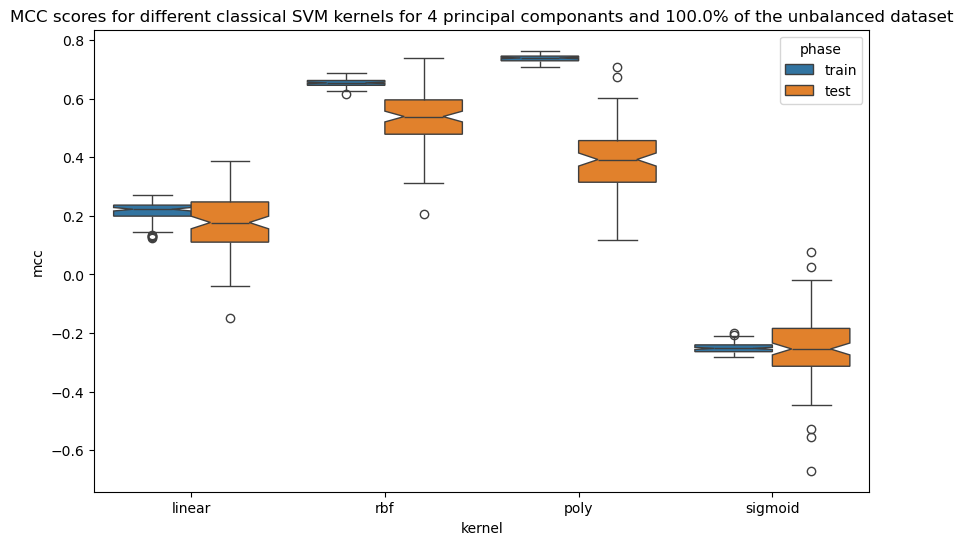

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
# sns.boxplot(x='gamma', y='mcc', hue='phase', data=stats_df[stats_df['kernel'] == 'rbf'], 
#             palette=palette, ax=ax)
sns.boxplot(x='kernel', y='mcc', hue='phase', data=stats_df, notch=True, ax=ax)
plt.title(f"MCC scores for different classical SVM kernels for {pca} principal componants and {float(percent)*100}% of the {balanced} dataset")
plt.savefig(Path("./images") / f"classical_svm_boxplot{extension}.png")
plt.show()

In [14]:
#data = stats_stdv['mcc']#['rbf']
data=stats_df[stats_df['kernel'] == 'rbf']

#display(data)
#data = stats_stdv[stats_stdv[kernel] == 'rbf']
ax = sns.lineplot(data=data, x= 'gamma', y='mcc',hue='phase', palette=palette)
ax.set_title("MCC vs gamma for " + extension)

ValueError: Could not interpret value `gamma` for `x`. An entry with this name does not appear in `data`.

In [ ]:
gamma_selected = 0.2

In [ ]:
ax = sns.violinplot(data=stats_df[stats_df['gamma'] == gamma_selected], 
                    x='kernel', y='mcc', 
                    hue='phase', palette=palette)
ax.set_title('MCC vs kernel for gamma=' + str(gamma_selected) + ' on ' + extension)

In [ ]:
data=stats_df[stats_df['kernel'] == 'rbf']
data = data[data['phase'] == 'test']
data = data[['gamma', 'true_healthy', 'false_healthy', 'true_failure', 'false_failure']]
data = data.melt('gamma', var_name='confusion', value_name='mcc')

ax = sns.lineplot(data=data, x= 'gamma', y='mcc', hue="confusion", palette=palette)
ax.set_title('Confusion Matrix vs gamma for the rbf kernel on ' + extension)

In [ ]:
data = stats_df[stats_df['gamma'] == gamma_selected][stats_df['kernel'] == 'rbf'][stats_df['phase']=='test'][['true_healthy', 'false_healthy', 'true_failure', 'false_failure']]

ax = sns.violinplot(data=data, palette=palette)
ax.set_title('Confusion Matrix for the rbf kernel and gamma=' + str(gamma_selected) + ' on ' + extension)